### (3) 전이 학습

- 전이 학습 : 이미지넷처럼 아주 큰 데이터셋을 써서 훈련된 모델의 가중치를 가져와 우리가 해결하려는 과제에 맞게 보정해서 사용하는 것
- 사전 훈련된 모델 : 아주 큰 데이터셋을 이용하여 훈련된 모델


**특성 추출 기법**
- 특성 추출: ImageNet 데이터셋으로 사전 훈련된 모델을 가져온 후 마지막에 완전연결층 부분만 새로 만드는 것
  - 합성곱층: 합성곱층과 풀링층으로 구성
  - 데이터 분류기(완전연결층): 추출된 특성을 입력받아 최종적으로 이미지에 대한 클래스를 분류하는 부분
  - 사용 가능한 이미지 분류 모델: Xception, Inception V3, ResNet50, VGG16, VGG19, MobileNet

In [1]:
!pip install opencv-python

In [2]:
# 라이브러리 호출
import os
import time
import copy
import glob
import cv2
import shutil

import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

In [3]:
import zipfile
import os

zip_path = '/content/train.zip'
extract_path = '/content/data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("압축 해제 완료!")

압축 해제 완료!


In [4]:
import os
import shutil

data_path = '/content/data/train'

os.makedirs(data_path + '/cat', exist_ok=True)
os.makedirs(data_path + '/dog', exist_ok=True)

for file in os.listdir(data_path):
    if file.endswith('.jpg'):
        if file.startswith('cat.'):
            shutil.move(data_path + '/' + file, data_path + '/cat/' + file)
        elif file.startswith('dog.'):
            shutil.move(data_path + '/' + file, data_path + '/dog/' + file)

In [5]:
# 이미지 데이터 전처리 방법 정의
data_path = '/content/data/train'

transform = transforms.Compose(
    [transforms.Resize([256, 256]),
     transforms.RandomResizedCrop(224),
     transforms.RandomHorizontalFlip(),
     transforms.ToTensor()]
)
train_dataset = torchvision.datasets.ImageFolder(
    data_path,
    transform=transform
)
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=32,
    num_workers=8,
    shuffle=True
)
print(len(train_dataset))

25000


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


- torchvision.transform : 이미지 데이터를 변환하여 모델의 입력으로 사용할 수 있게 변환
  - Resize: 이미지의 크기를 조정
  - RandomResizedCrop: 이미지를 랜덤한 크기 및 비율로 자름
  - RandomHorizontalFlip: 이미지를 랜덤하게 수평으로 뒤집음
  - ToTensor: 이미지 데이터를 텐서로 변환
- datasets.ImageFolder: 데이터로더가 데이터를 불러올 대상과 방법을 정의
  - 첫 번째 파라미터: 불러올 데이터가 위치한 경로
  - transform: 이미지 데이터에 대한 전처리
- 데이터로더: 데이터를 불러오는 부분
  - 첫 번째 파라미터: 데이터셋을 지정
  - batch_size: 한 번에 불러올 데이터양을 결정하는 배치 크기를 설정
  - num_workers: 데이터를 불러올 때 몇 개의 하위 프로세스를 사용할지 설정
  - shuffle: 데이터를 무작위로 섞을지를 지정

[RandomResizedCrop]
- 데이터를 확장

- !pip install mxnet

- !pip install --user mxnet

In [6]:
import numpy as np

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


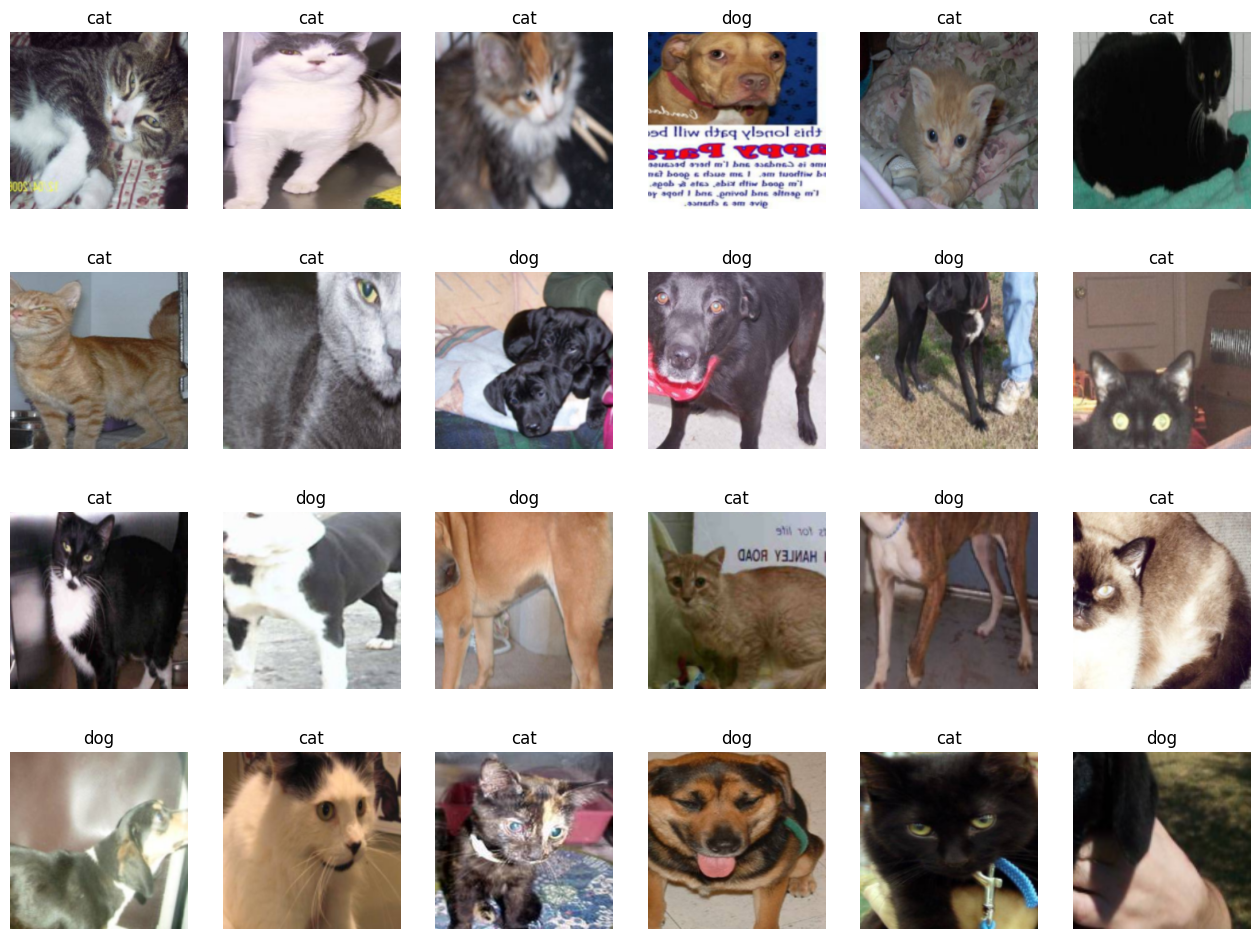

In [7]:
# 학습에 사용될 이미지 출력
samples, labels = next(iter(train_loader))
classes = {0:'cat', 1:'dog'}
fig = plt.figure(figsize=(16,24))
for i in range(24):
  a = fig.add_subplot(4,6,i+1)
  a.set_title(classes[labels[i].item()])
  a.axis('off')
  a.imshow(np.transpose(samples[i].numpy(), (1,2,0)))
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)

- 반복자: iter(), next() 필요
  - iter(): 전달된 데이터의 반복자를 꺼내 반환
  - next(): 반복자가 다음에 출력해야 할 요소 반환
- np.transpose: 행과 열을 바꿈으로써 행렬의 차원을 바꾸어줌

In [8]:
# 사전 훈련된 모델 내려받기
resnet18 = models.resnet18(pretrained=True)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 154MB/s]


[ResNet18]
- 50개의 계층으로 구성된 합성곱 신경망
- 전이 학습에 사용되도록 사전 훈련된 모델을 제공
- 다만 입력 제약이 매우 크고 충분한 메모리가 없으면 학습 속도가 느릴 수 있음

In [9]:
# 사전 훈련된 모델의 파라미터 학습 유무 지정
def set_parameter_requires_grad(model, feature_extracting=True):
  if feature_extracting:
    for param in model.parameters():
      param.requires_grad = False

set_parameter_requires_grad(resnet18)

- requires_grad = False: 모델의 일부를 고정하고 나머지를 학습하고자 할 때

In [10]:
# ResNet18에 완전연결층 추가
resnet18.fc = nn.Linear(512, 2)

In [11]:
# 모델의 파라미터 값 확인
for name, param in resnet18.named_parameters():
  if param.requires_grad:
    print(name, param.data)

fc.weight tensor([[ 0.0401,  0.0347,  0.0023,  ...,  0.0374, -0.0162, -0.0031],
        [ 0.0026, -0.0102, -0.0151,  ..., -0.0064, -0.0367, -0.0332]])
fc.bias tensor([-0.0275,  0.0266])


In [12]:
# 모델 객체 생성 및 손실 함수 정의
model = models.resnet18(pretrained=True)

for param in model.parameters():
  param.requires_grad = False

model.fc = torch.nn.Linear(512, 2)
for param in model.fc.parameters():
  param.requires_grad = True

optimizer = torch.optim.Adam(model.fc.parameters())
cost = torch.nn.CrossEntropyLoss()
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [19]:
# 모델 학습을 위한 함수 생성
def train_model(model, dataloaders, criterion, optimizer, device, num_epochs=13,
                is_train=True):
  since = time.time()
  acc_history = []
  loss_history = []
  best_acc = 0.0

  for epoch in range(num_epochs):
    print('Epoch {}/{}'.format(epoch, num_epochs-1))
    print('-' * 10)

    running_loss = 0.0
    running_corrects = 0

    for inputs, labels in dataloaders:
      inputs = inputs.to(device)
      labels = labels.to(device)

      model.to(device)
      optimizer.zero_grad()
      outputs = model(inputs)
      loss = criterion(outputs, labels)
      _, preds = torch.max(outputs, 1)
      loss.backward()
      optimizer.step()

      running_loss += loss.item() * inputs.size(0)
      running_corrects += torch.sum(preds == labels.data)

    epoch_loss = running_loss / len(dataloaders.dataset)
    epoch_acc = running_corrects.double() / len(dataloaders.dataset)

    print('Loss: {:.4f} Acc: {:.4f}'.format(epoch_loss, epoch_acc))

    if epoch_acc > best_acc:
      best_acc = epoch_acc

    acc_history.append(epoch_acc.item())
    loss_history.append(epoch_loss)
    torch.save(model.state_dict(), os.path.join('/content/data/',
                                                '{0:0=2d}.pth'.format(epoch)))
    print()

  time_elapsed = time.time() - since
  print('Training complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60,
                                                      time_elapsed % 60))
  print('Best Acc: {:4f}'.format(best_acc))
  return acc_history, loss_history

In [20]:
# 파라미터 학습 결과를 옵티마이저에 전달
params_to_update = []
for name, param in resnet18.named_parameters():
  if param.requires_grad == True:
    params_to_update.append(param)
    print("\t", name)

optimizer = optim.Adam(params_to_update)

	 fc.weight
	 fc.bias


In [21]:
# 모델 학습
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()
train_acc_hist, train_loss_hist = train_model(resnet18, train_loader, criterion,
                                              optimizer, device)

Epoch 0/12
----------


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Loss: 0.1507 Acc: 0.9366

Epoch 1/12
----------
Loss: 0.1563 Acc: 0.9317

Epoch 2/12
----------
Loss: 0.1459 Acc: 0.9368

Epoch 3/12
----------
Loss: 0.1490 Acc: 0.9349

Epoch 4/12
----------
Loss: 0.1435 Acc: 0.9380

Epoch 5/12
----------
Loss: 0.1521 Acc: 0.9334

Epoch 6/12
----------
Loss: 0.1485 Acc: 0.9357

Epoch 7/12
----------
Loss: 0.1513 Acc: 0.9343

Epoch 8/12
----------
Loss: 0.1471 Acc: 0.9365

Epoch 9/12
----------
Loss: 0.1529 Acc: 0.9350

Epoch 10/12
----------
Loss: 0.1538 Acc: 0.9349

Epoch 11/12
----------
Loss: 0.1511 Acc: 0.9372

Epoch 12/12
----------
Loss: 0.1495 Acc: 0.9360

Training complete in 26m 45s
Best Acc: 0.937960


In [22]:
import zipfile
import os

zip_path = '/content/test1.zip'
extract_path = '/content/data/test1'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("압축 해제 완료!")

압축 해제 완료!


In [23]:
# 테스트 데이터 호출 및 전처리
test_path = '/content/data/test1'

transform = transforms.Compose(
    [
        transforms.Resize(224),
        transforms.CenterCrop(224),
        transforms.ToTensor()
    ]
)

test_dataset = torchvision.datasets.ImageFolder(
    root=test_path,
    transform=transform
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=32,
    num_workers=1,
    shuffle=True
)

print(len(test_dataset))

12500


In [28]:
# 테스트 데이터 평가 함수 생성
def eval_model(model, dataloaders, device):
    since = time.time()
    acc_history = []
    best_acc = 0.0

    saved_models = glob.glob('/content/data/' + '*.pth')
    saved_models.sort()
    print('saved_model', saved_models)

    for model_path in saved_models:
        print('Loading model', model_path)

        model.load_state_dict(torch.load(model_path))
        model.eval()
        model.to(device)
        running_corrects = 0

        for inputs, labels in dataloaders:
            inputs = inputs.to(device)
            labels = labels.to(device)

            with torch.no_grad():
                outputs = model(inputs)

            _, preds = torch.max(outputs.data, 1)
            preds[preds >= 0.5] = 1
            preds[preds < 0.5] = 0
            running_corrects += preds.eq(labels).int().sum()

        epoch_acc = running_corrects.double() / len(dataloaders.dataset)
        print('Acc: {:.4f}'.format(epoch_acc))

        if epoch_acc > best_acc:
            best_acc = epoch_acc

        acc_history.append(epoch_acc.item())
        print()

    time_elapsed = time.time() - since
    print('Validation complete in {:.0f}m {:.0f}s'.format(
        time_elapsed // 60, time_elapsed % 60))

    print('Best Acc: {:.4f}'.format(best_acc))

    return acc_history

In [29]:
# 테스트 데이터를 평가 함수에 적용
val_acc_hist = eval_model(resnet18, test_loader, device)

saved_model ['/content/data/00.pth', '/content/data/01.pth', '/content/data/02.pth', '/content/data/03.pth', '/content/data/04.pth', '/content/data/05.pth', '/content/data/06.pth', '/content/data/07.pth', '/content/data/08.pth', '/content/data/09.pth', '/content/data/10.pth', '/content/data/11.pth', '/content/data/12.pth']
Loading model /content/data/00.pth
Acc: 0.4992

Loading model /content/data/01.pth
Acc: 0.4959

Loading model /content/data/02.pth
Acc: 0.5043

Loading model /content/data/03.pth
Acc: 0.5050

Loading model /content/data/04.pth
Acc: 0.4975

Loading model /content/data/05.pth
Acc: 0.4975

Loading model /content/data/06.pth
Acc: 0.5004

Loading model /content/data/07.pth
Acc: 0.4962

Loading model /content/data/08.pth
Acc: 0.4894

Loading model /content/data/09.pth
Acc: 0.4799

Loading model /content/data/10.pth
Acc: 0.5006

Loading model /content/data/11.pth
Acc: 0.4943

Loading model /content/data/12.pth
Acc: 0.4957

Validation complete in 10m 54s
Best Acc: 0.5050


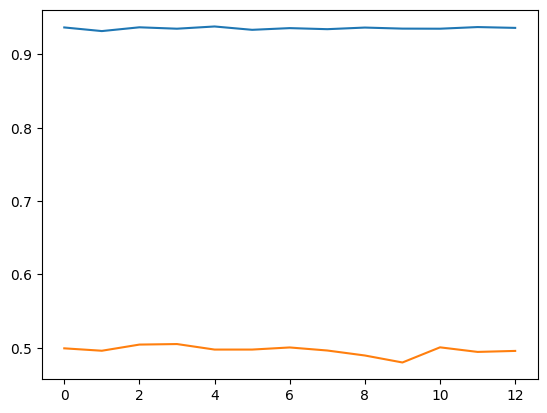

In [31]:
# 훈련과 테스트 데이터의 정확도를 그래프로 확인
plt.plot(train_acc_hist)
plt.plot(val_acc_hist)
plt.show()

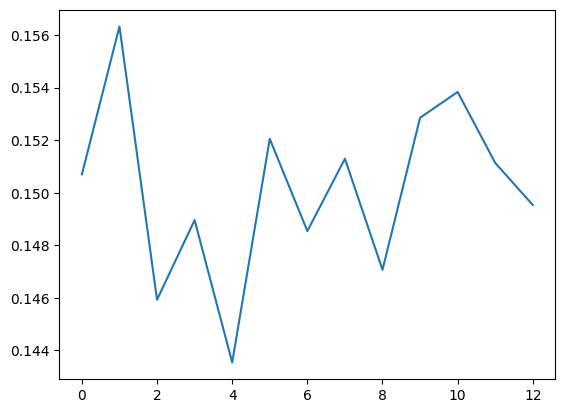

In [32]:
# 훈련 데이터의 오차에 대한 그래프 확인
plt.plot(train_loss_hist)
plt.show()

In [33]:
# 예측 이미지 출력을 위한 전처리 함수
def im_convert(tensor):
    image = tensor.clone().detach().numpy()  # ①
    image = image.transpose(1, 2, 0)
    image = image * (np.array((0.5,0.5,0.5)) + np.array((0.5,0.5,0.5)))
    image = image.clip(0, 1)  # ②
    return image

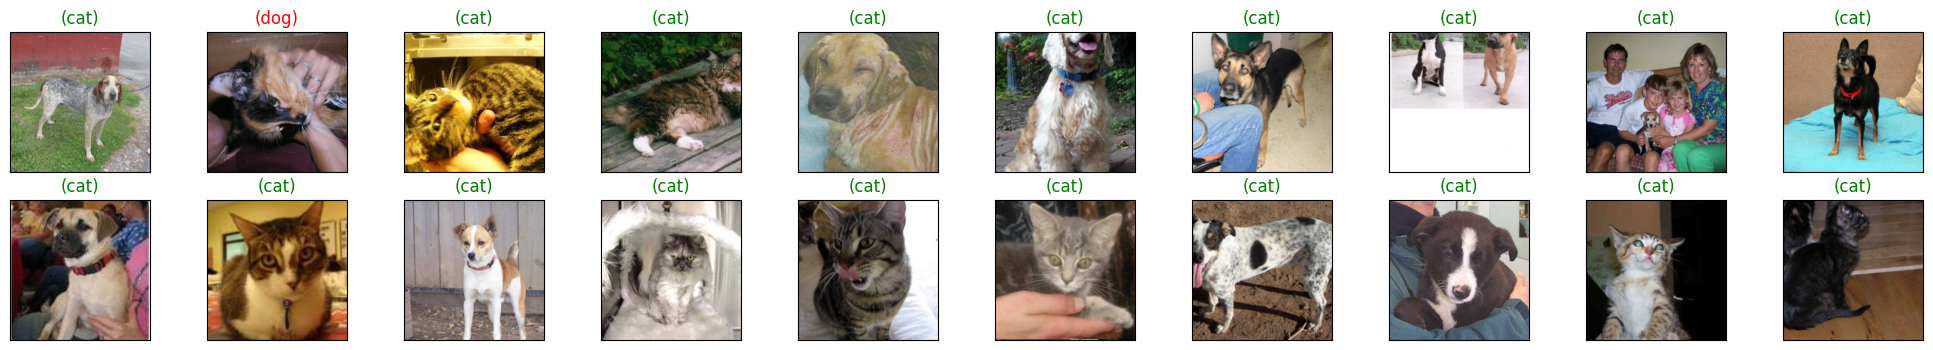

<Figure size 640x480 with 0 Axes>

In [34]:
# 개와 고양이 예측 결과 분석
classes = {0:'cat', 1:'dog'}

dataiter = iter(test_loader)
images, labels = next(dataiter)
output = model(images)
_, preds = torch.max(output, 1)

fig = plt.figure(figsize=(25,4))
for idx in np.arange(20):
    ax = fig.add_subplot(2, 10, idx+1, xticks=[], yticks=[])  # ①
    plt.imshow(im_convert(images[idx]))
    ax.set_title(classes[labels[idx].item()])
    ax.set_title("({})".format(str(classes[preds[idx].item()]), str(classes[labels[idx].item()])),
                 color=("green" if preds[idx]==labels[idx] else "red"))  # ②

plt.show()
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)  # ③

**미세 조정 기법**
- 정의: 사전 학습된 모델의 가중치를 목적에 맞게 추가 학습시키는 기법.



- 특징 추출과 차이: 특성 추출은 기존 가중치를 고정하지만, 미세 조정은 합성곱층과 분류기의 가중치를 업데이트함.



- 목적: 새로운 데이터셋에 맞게 특성을 다시 학습하여 성능을 높임.



- 주의: 연산량이 많아 GPU 사용을 권장함.

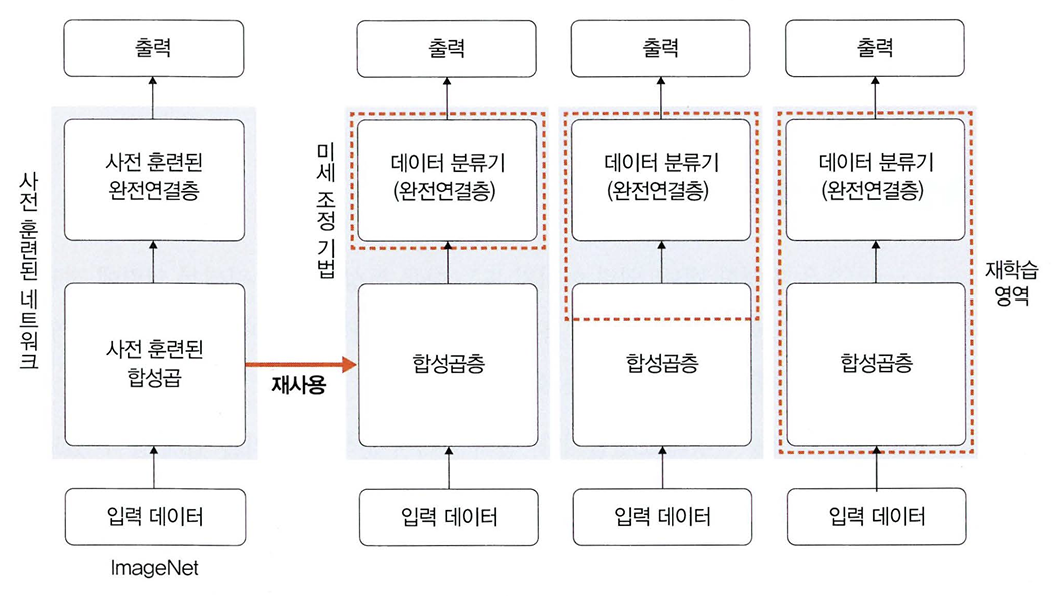